# iQ-Index Tracking figures for sales presentations.

In this notebook we generate figures to showcase the results of our product iQ-Index Tracking.

In [1]:
from dataclasses import dataclass, field
import glob
from pathlib import Path
import os

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

In [2]:
CWD = Path.cwd()

# Using the Montserrat font from Google fonts

This is the font that we use to make decks and showcase results. Download instructions:

1. Go to [Google Fonts-Montserrat](https://fonts.google.com/specimen/Montserrat)
2. Click in "Get front" and install the font in `$HOME/fonts/Montserrat.zip`.
3. Unzip it in the same folder.

In [3]:
FONT_PATH = Path.home() / "fonts" / "Montserrat"


def register_font_family() -> None:
    """Register all font files in a folder with matplotlib."""
    font_files = glob.glob(f"{FONT_PATH}/static/*.ttf")
    print(font_files)
    for font_file in font_files:
        fm.fontManager.addfont(font_file)
    # Rebuild font cache
    fm._get_fontconfig_fonts.cache_clear()
    return


register_font_family()

# Make matplotlib use Montserrat
plt.rcParams.update({"font.family": "Montserrat", "font.weight": "regular"})

['/home/arubio/fonts/Montserrat/static/Montserrat-SemiBold.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-Light.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-ExtraLight.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-Italic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-BlackItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-ExtraBoldItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-ExtraBold.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-Bold.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-SemiBoldItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-ExtraLightItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-Black.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-ThinItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-MediumItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-BoldItalic.ttf', '/home/arubio/fonts/Montserrat/static/Montserrat-LightItalic.ttf', '/home/arubio

## Data loading

Instead of generating the data in this notebook, we load the data from a CSV. In this way the user only needs to install pandas and matplotlib to run the notebook.


In [ ]:
def plot_tracker_portfolio_kpis(portfolio_size: int) -> None:
    """Plot several KPIs of the iQ-Index Tracking portfolios for the SP-500.

    Plot:
    1. Daily Net Asset Value (NAV) of the SP-500 and of the portfolio.
    2. Daily active return: daily return of the portfolio minus the daily return of the SP-500.

    """
    # Load the data.
    portfolio_df = pd.read_csv(
        f"iQ-Index_Tracking-SP500-size_{portfolio_size}.csv", index_col=0, parse_dates=True
    )

    portfolio_NAV = portfolio_df["portfolio_net_asset_value"]
    benchmark_NAV = portfolio_df["benchmark_net_asset_value"]
    active_return = portfolio_df["active_return"]
    start_date = portfolio_df.index[0]

    # PLOT
    lfs = 16  # labelfontsize
    tfs = 12  # tickfontsize
    iQ_color = "#0066ff"  # iQ color

    # Figure definition, size and format.
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)

    # Line plots.
    ax[0].plot(benchmark_NAV, "--k", lw=1.5, label="SP-500")
    ax[0].plot(portfolio_NAV, "-", c=iQ_color, lw=1, mfc="w", label="iQ Index Tracking")
    ax[1].plot(active_return, "-", c=iQ_color, lw=1, mfc="w")

    # Titles, axis labels and legend.
    title_str = f"Portfolio of size {portfolio_size} tracking the SP-500 with quarterly rebalance"
    ax[0].set_title(title_str, family="Montserrat", fontsize=lfs, color="0.3", fontweight="normal", pad=15)
    ax[0].set_ylabel(f"Performance since\n{start_date} (%)", fontsize=tfs, color="0.3")
    ax[1].set_ylabel("Excess return (%)", fontsize=tfs, color="0.3")
    legend = ax[0].legend(ncols=2, loc="upper left", fontsize=tfs, title_fontsize=tfs)
    plt.setp(legend.get_texts(), color="0.3")

    for i in range(len(ax)):
        ax[i].grid(c="0.9")
        # Set the ticks of both axes to the same fontsize and color.
        ax[i].tick_params(axis="both", which="major", labelsize=tfs, colors="0.3")
        # Set spine (frame) color to light gray
        for spine in ax[i].spines.values():
            spine.set_edgecolor("0.8")

    plt.savefig(f"plot_portfolio_{portfolio_size}.png", dpi=400, bbox_inches='tight')
    plt.show()

    return

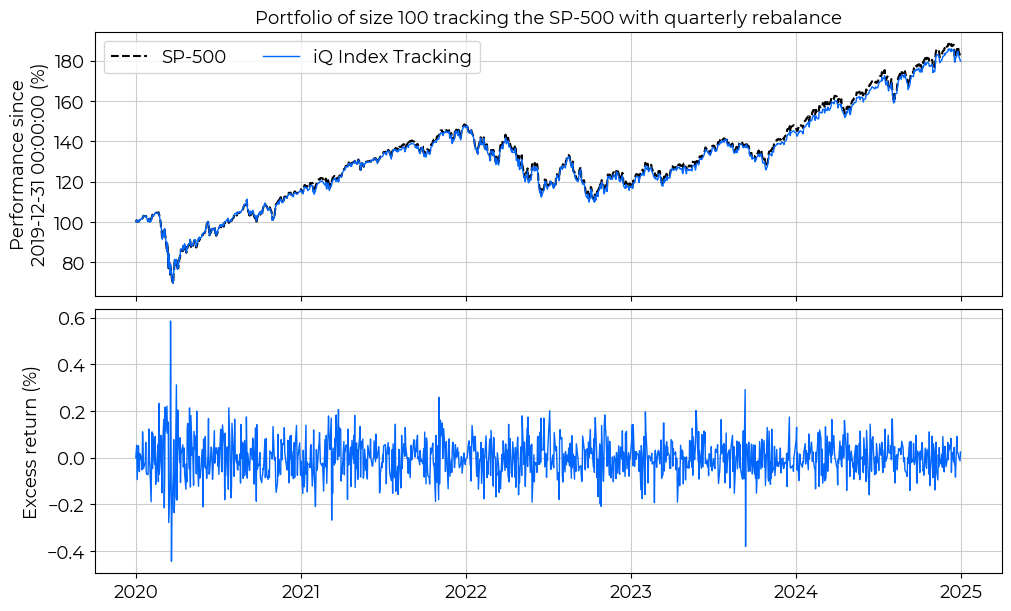

In [5]:
plot_tracker_portfolio_kpis(portfolio_size=100)

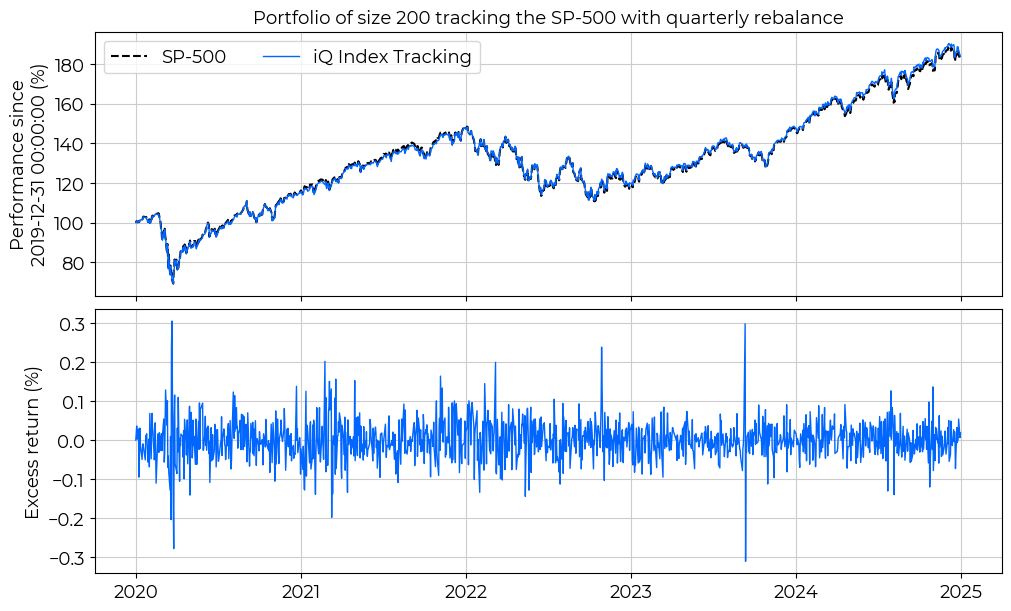

In [6]:
plot_tracker_portfolio_kpis(portfolio_size=200)